<a href="https://colab.research.google.com/github/rybak97/free_courses/blob/main/Genetic_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Genetic algorithm designed to maximize the function:
$$f(x, y) = -x^2 + y^2 - 2xy$$
within the range $x, y \in [-8, 8]$.



In [16]:
import random
import numpy as np
from numpy.random import randint, rand
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Target function definition (function to maximize)
def fun(x):
    return -x[0]**2.0 + x[1]**2.0 - 2 * x[0] * x[1]

# Variables boundaries
scope = [[-8.0, 8.0], [-8.0, 8.0]]

### Genetic Algorithm Parameters and Genotype Decoding

In [17]:
# Optimization Parameters
n_gen = 8      # Number of bits per variable (16 bits total per individual)
n_pop = 40     # Population size
n_iter = 60    # Number of generations
pk = 0.9       # Crossover probability
pm = 0.05      # Mutation probability

def decode(scope, n_gen, bitstring):
    decoded = list()
    largest = 2**n_gen - 1 # Adjusted to 2^n - 1 to cover the full boundary range correctly

    for i in range(len(scope)):
        start, end = i * n_gen, (i * n_gen) + n_gen
        substring = bitstring[start:end]

        chars = ''.join([str(s) for s in substring])
        integer = int(chars, 2)

        # Linear scaling to the boundary values
        value = scope[i][0] + (integer / largest) * (scope[i][1] - scope[i][0])
        decoded.append(value)

    return decoded

### Genetic Operators: Crossover, Mutation, and Selection Methods

In [18]:
def cross(p1, p2, pk):
    c1, c2 = p1.copy(), p2.copy()
    if rand() < pk:
        # Two-point crossover
        k = randint(1, len(p1) // 2)
        m = randint((len(p1) // 2) + 1, len(p1) - 1)
        c1 = p1[:k] + p2[k:m] + p1[m:]
        c2 = p2[:k] + p1[k:m] + p2[m:]
    return [c1, c2]

def mutation(bitstring, pm):
    for i in range(len(bitstring)):
        if rand() < pm:
            bitstring[i] = 1 - bitstring[i] # Invert the bit value

# Ranking Selection
def selection_ranking(pop, scores, k=10):
    # Sort population in ascending order of scores (best individuals at the end)
    sorted_pop = [y for _, y in sorted(zip(scores, pop), key=lambda x: x[0])]
    # Replace the k worst individuals with copies of the k best individuals
    sorted_pop[0:k] = sorted_pop[len(sorted_pop)-k : len(sorted_pop)]
    return sorted_pop

# Roulette Wheel Selection
def selection_roulette(pop, scores):
    min_s = min(scores)
    max_s = max(scores)
    denom = (max_s - min_s) if (max_s - min_s) != 0 else 1.0

    # Offset and normalize scores to ensure positive probabilities
    scores_normalized = [score - min_s for score in scores]
    sum_scores = sum(scores_normalized)

    if sum_scores == 0:
        probabilities = [1.0 / len(pop)] * len(pop)
    else:
        probabilities = [score / sum_scores for score in scores_normalized]

    # Spin the roulette wheel to select individuals
    selected_indices = np.random.choice(len(pop), size=len(pop), p=probabilities)
    return [pop[idx].copy() for idx in selected_indices]

### Main Genetic Algorithm Loop (with progress improvement logs)

In [19]:
def genetic_algorithm(fun, scope, n_gen, n_iter, n_pop, pk, pm, selection_type):
    # Initialize population with random bits
    pop = [randint(0, 2, n_gen * 2).tolist() for _ in range(n_pop)]

    best, best_eval = None, -float('inf')
    history = []

    for g in range(n_iter):
        # Decode chromosomes and evaluate fitness
        decoded = [decode(scope, n_gen, p) for p in pop]
        scores = [fun(ind) for ind in decoded]

        # Track and print if a new global best score is reached
        improved = False
        for i in range(n_pop):
            if scores[i] > best_eval:
                best, best_eval = pop[i].copy(), scores[i]
                improved = True

        if improved:
            best_decoded = decode(scope, n_gen, best)
            print(f'>{g}, best f({best_decoded}) = {best_eval:.6f}')

        history.append(best_eval)

        # Selection step
        if selection_type == "ranking":
            pop = selection_ranking(pop, scores)
        elif selection_type == "roulette":
            pop = selection_roulette(pop, scores)

        # Reproduction phase (Crossover and Mutation)
        next_generation = []
        for i in range(0, n_pop, 2):
            if i + 1 < n_pop:
                p1, p2 = pop[i], pop[i+1]
                for child in cross(p1, p2, pk):
                    mutation(child, pm)
                    next_generation.append(child)
            else:
                next_generation.append(pop[i])
        pop = next_generation

    return best, best_eval, history

### Executing Experiments for Both Selection Methods

In [20]:
print("=== Running Roulette Wheel Selection ===")
best_r, score_r, history_r = genetic_algorithm(fun, scope, n_gen, n_iter, n_pop, pk, pm, "roulette")
decoded_r = decode(scope, n_gen, best_r)
print(f"Final Best Result: f({decoded_r}) = {score_r:.6f}\n")

print("=== Running Ranking Selection ===")
best_rank, score_rank, history_rank = genetic_algorithm(fun, scope, n_gen, n_iter, n_pop, pk, pm, "ranking")
decoded_rank = decode(scope, n_gen, best_rank)
print(f"Final Best Result: f({decoded_rank}) = {score_rank:.6f}")

=== Running Roulette Wheel Selection ===
>0, best f([-5.552941176470588, 8.0]) = 122.011903
>18, best f([-7.309803921568627, 7.874509803921569]) = 123.696917
>19, best f([-7.372549019607844, 7.9372549019607845]) = 125.681138
>23, best f([-7.435294117647059, 7.9372549019607845]) = 125.748066
>24, best f([-7.811764705882353, 7.9372549019607845]) = 125.984283
>41, best f([-7.811764705882353, 8.0]) = 127.964567
>58, best f([-7.874509803921569, 8.0]) = 127.984252
Final Best Result: f([-7.874509803921569, 8.0]) = 127.984252

=== Running Ranking Selection ===
>0, best f([-5.364705882352942, 8.0]) = 121.055225
>4, best f([6.807843137254903, -8.0]) = 126.578762
>8, best f([7.12156862745098, -8.0]) = 127.228358
>9, best f([7.623529411764705, -8.0]) = 127.858270
>11, best f([7.749019607843136, -8.0]) = 127.937009
>14, best f([7.874509803921569, -8.0]) = 127.984252
>18, best f([8.0, -8.0]) = 128.000000
Final Best Result: f([8.0, -8.0]) = 128.000000


### Comparative Analysis and 3D Visualizations

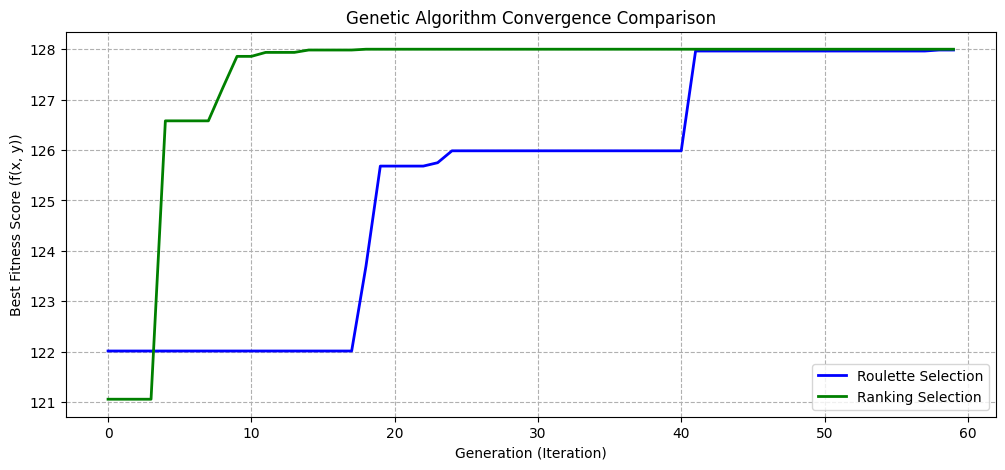

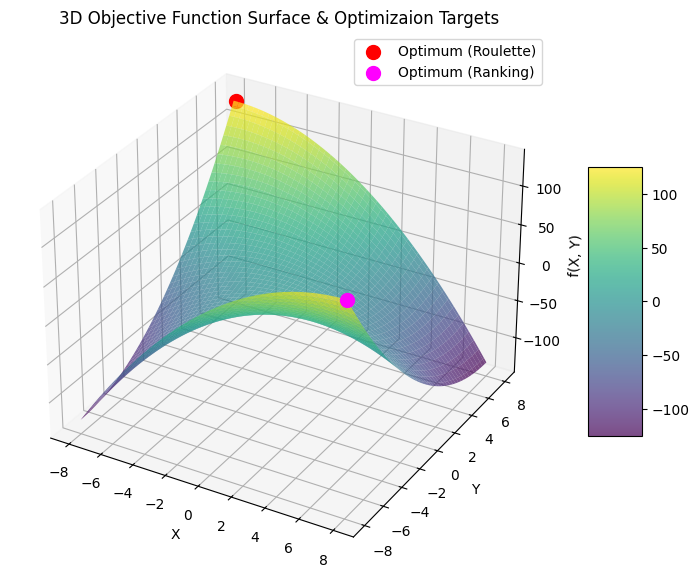

In [21]:
# 1. Convergence curve per generation
plt.figure(figsize=(12, 5))
plt.plot(history_r, label='Roulette Selection', color='blue', linewidth=2)
plt.plot(history_rank, label='Ranking Selection', color='green', linewidth=2)
plt.title('Genetic Algorithm Convergence Comparison')
plt.xlabel('Generation (Iteration)')
plt.ylabel('Best Fitness Score (f(x, y))')
plt.grid(True, linestyle='--')
plt.legend()
plt.show()

# 2. 3D Surface map of the search space with optimal points
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

x = np.linspace(-8, 8, 100)
y = np.linspace(-8, 8, 100)
X, Y = np.meshgrid(x, y)
Z = -X**2.0 + Y**2.0 - 2 * X * Y

surf = ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.7, edgecolor='none')
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5)

# Plot the discovered optima positions
ax.scatter(decoded_r[0], decoded_r[1], score_r, color='red', s=100, label='Optimum (Roulette)', depthshade=False)
ax.scatter(decoded_rank[0], decoded_rank[1], score_rank, color='magenta', s=100, label='Optimum (Ranking)', depthshade=False)

ax.set_title('3D Objective Function Surface & Optimizaion Targets')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('f(X, Y)')
ax.legend()
plt.show()